In [1]:
# 불순도를 최소화하도록 하는 최적의 코드로 실행했을 때의 정확도, 예측할 것: 의사결정나무

In [2]:
# GridSearchCV를 이용한 최소화

In [3]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV

In [4]:
df = pd.read_csv('../data/wine.csv')
df.head(2)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [5]:
data = df[df.columns[:3]].values
data[:2]

array([[9.4 , 1.9 , 3.51],
       [9.8 , 2.6 , 3.2 ]])

In [6]:
label = df['class'].values
label[:2]

array([0., 0.])

In [7]:
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42)

In [8]:
dt = DecisionTreeClassifier(random_state=42)
params = {'min_impurity_decrease':np.arange(0.00001,0.00005,0.00001)}
gs = GridSearchCV(dt,params,n_jobs=-1)
gs.fit(train_data,train_label)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'min_impurity_decrease': array([1.e-05...e-05, 4.e-05])}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of information 

In [9]:
dt = gs.best_estimator_
dt.fit(train_data,train_label)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",np.float64(4e-05)
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",N

In [10]:
# 불순도 측정 간격 결정에 참고 -> 쪼갠 0.00001보다 정확도 차이가 크지만 전체적인 판정에는 큰 변화없음
print('train:',dt.score(train_data,train_label))
print('test:',gs.cv_results_['mean_test_score'])

train: 0.9901477832512315
test: [0.85529785 0.8585799  0.85755363 0.85919486]


In [11]:
# 정확도 확인
print('train:',dt.score(train_data,train_label))
print('test:',dt.score(test_data,test_label))

train: 0.9901477832512315
test: 0.8541538461538462


In [12]:
predict = dt.predict(test_data[:3])
predict

array([1., 0., 1.])

In [13]:
proba = dt.predict_proba(test_data)
proba[:3]

array([[0.00866667, 0.99133333],
       [1.        , 0.        ],
       [0.00866667, 0.99133333]])

In [14]:
print('실제 트리 깊이:',dt.get_depth())

실제 트리 깊이: 24


In [15]:
print('리프 노드 개수:',dt.get_n_leaves())

리프 노드 개수: 646


In [11]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [13]:
# 데이터 가져오기
wine = pd.read_csv('../data/wine.csv')
wine.head(2)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [14]:
data = wine[wine.columns[:-1]].values
label = wine['class'].values

In [15]:
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42)

In [21]:
params = {
    'max_depth': range(5,10,1),
    'min_impurity_decrease' : np.arange(0.0001,0.0005,0.001),
    'min_samples_split':range(2,100,10)
}

In [24]:
gs = GridSearchCV(DecisionTreeClassifier(random_state=42),params,n_jobs=-1,return_train_score=True)
gs.fit(train_data,train_label)

dt = gs.best_estimator_ # 최고 성능모델

print("train정확도:",dt.score(train_data,train_label))  # 최고 모델을 적용한 훈련데이터 정확도
print("test정확도:",dt.score(test_data,test_label))     # 최고 모델을 적용한 테스트데이터 정확도

print('가장 좋은 파라미터:',gs.best_params_)              # 점수가 가장 높았던 파라미터

print(gs.cv_results_['mean_train_score'])  # 파라미터 조합을 교차검증 시 평균점수(모든 경우의 수, 최고 cv아니라 cv)
print(gs.cv_results_['mean_test_score'])   # 파라미터 조합을 교차검증 시 평균점수(모든 경우의 수, 최고 cv아니라 cv)

train정확도: 0.9039408866995073
test정확도: 0.8603076923076923
가장 좋은 파라미터: {'max_depth': 9, 'min_impurity_decrease': np.float64(0.0001), 'min_samples_split': 22}
[0.87376842 0.87376842 0.87376842 0.8730501  0.8730501  0.87284487
 0.87274225 0.87274225 0.87274225 0.87274225 0.88146527 0.88131131
 0.88028505 0.87915622 0.87864307 0.87792466 0.87633397 0.87628265
 0.87628265 0.87628265 0.89167672 0.89008602 0.88690457 0.88526265
 0.88444161 0.88300477 0.88074707 0.88023385 0.88007993 0.8793103
 0.90440234 0.89947634 0.89465284 0.89172806 0.88921378 0.88659679
 0.8839799  0.88331272 0.88254308 0.8812603  0.92015554 0.90979039
 0.90122099 0.89598707 0.89285706 0.88977825 0.88675087 0.88608369
 0.88485225 0.8832103 ]
[0.85837161 0.85837161 0.85837161 0.85755026 0.85755026 0.85713958
 0.85693424 0.85693424 0.85693424 0.85693424 0.86699437 0.86740504
 0.86843153 0.86719971 0.86576297 0.86514716 0.86514674 0.86514674
 0.86514674 0.86514674 0.86268309 0.86329911 0.86761101 0.866995
 0.86576339 0.86514

In [1]:
# 제약조건을 둔 GridSearchCV를 이용한 코드

In [3]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV

In [4]:
df = pd.read_csv('../data/wine.csv')
df.head(2)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [5]:
data = df[df.columns[:3]].values
data[:2]

array([[9.4 , 1.9 , 3.51],
       [9.8 , 2.6 , 3.2 ]])

In [6]:
label = df['class'].values
label[:2]

array([0., 0.])

In [16]:
# 반복문을 이용한 불순도 최소화

In [17]:
df = pd.read_csv('../data/wine.csv')
df.head(2)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [18]:
data = df[df.columns[:3]].values
data[:2]

array([[9.4 , 1.9 , 3.51],
       [9.8 , 2.6 , 3.2 ]])

In [19]:
label = df['class'].values
label[:2]

array([0., 0.])

In [25]:
# 데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label,test_size=0.2,random_state=42)

In [ ]:
for i in np.arange(0.0001,0.0005,0.0001):
    dt = DecisionTreeClassifier(min_impurity_decrease=i, \
                                min_samples_split=1, max_depth=2,random_state=42)
    # depth에 따라 train_data을 쪼개는데, 쪼개기 위해 최소한 필요한 자료갯수(min_samples_split)는 2개
    # max_depth = 1 최대 쪼갤 수 있는 횟수는 1회(0이 될 수도 있음. 불순도 감소분이 i증가분보다 작으면..)
    dt.fit(train_data,train_label)
    print(i)
    print('train정확도:',dt.score(train_data,train_label))
    print('test정확도:',dt.score(test_data,test_label))

0.0001
train정확도: 0.8098903213392342
test정확도: 0.7961538461538461
0.0002
train정확도: 0.8098903213392342
test정확도: 0.7961538461538461
0.00030000000000000003
train정확도: 0.8098903213392342
test정확도: 0.7961538461538461
0.0004
train정확도: 0.8098903213392342
test정확도: 0.7961538461538461


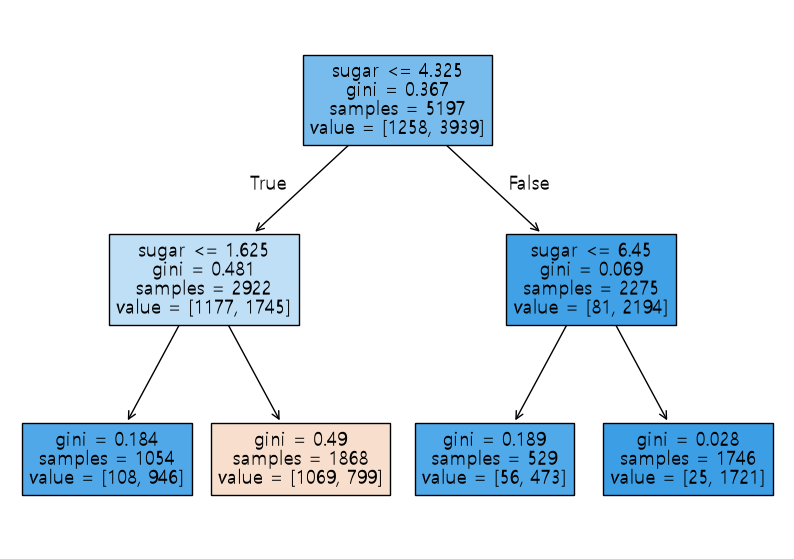

In [29]:
plt.figure(figsize=(10,7))
plot_tree(dt,max_depth=2,filled=True,feature_names=['alcohol','sugar','pH'])
plt.show()

In [24]:
print('train정확도:', dt.score(train_data,train_label))
print('test정확도:', dt.score(test_data,test_label))

train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
